## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [57]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Andrew Kim

**Date:** 10/19/2026

In [64]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.decomposition import PCA

### Q1 

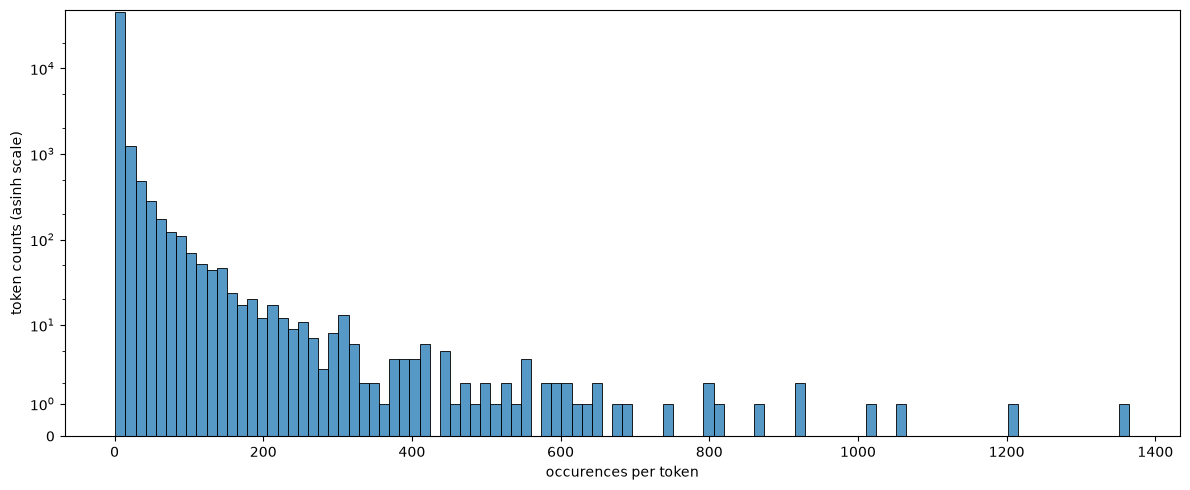

In [59]:
# q1
words, word_counts = zip(*token_freq)

plt.figure(figsize=(12,5))
sns.histplot(data=word_counts, bins=100)
plt.yscale('asinh')
plt.xlabel('occurences per token')
plt.ylabel('token counts (asinh scale)')
plt.tight_layout()
plt.show()

**q1** The histogram is stongly right skewed. A majority of the token counts are very infrequent with only a small minority of token counts being very frequent and taking up a majority of the data. The distribution of the tokens drops off sharply, continuing to decline with a long tail towards high occurences. This suggests that most words are used infrequently while a select group of words are continuely used over and over.

In [60]:
# q2
df = pd.read_parquet('data/Phishing_clean.parquet')
df.isna().sum().sum()
df.shape
df.head(1)

,Email Type,new,date,get,please,enron,like,2002,would,one,...,ï¿½ï¿½,safety,yap,ypil,maintain,procedures,tip,elizabeth,leadership,italian
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Q2

In [88]:
# q2
x = df.drop(columns=['Email Type'])
y = df['Email Type']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(x_train, y_train)

train_r2 = model.score(x_train, y_train)
print(f'training r2 score: {train_r2:.4f}')

test_r2 = model.score(x_test, y_test)
print(f'test r2 score: {test_r2:.4f}')

training r2 score: 0.7670
test r2 score: 0.6659


In [62]:
# q2
train_words = x.columns.tolist()
coefficients = pd.Series(model.coef_, index = train_words)
coefficients.head()

magnitudes = coefficients.abs().sort_values(ascending=False)
magnitudes.head()

strongest = coefficients.loc[magnitudes.index]
print(f'most influential coefficients:\n{strongest.head()}')

most influential coefficients:
intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
dtype: float64


**q2** The five words that have the largest coefficients/impact on the prediction model are: 'intervention', 'localized', 'thermal', 'crawler', and 'background-image:'. Of these 'intervention' and 'background-image:' have negative values indicating that they push the prediction towards being non scam mail while the other words push the prediction towards being scam mails.

In [72]:
# q3
pca_2 = PCA(n_components=2)
pc_scores = pca_2.fit_transform(x)
pc_scores.shape

plot_df = pd.DataFrame(
    pc_scores,
    columns=['PC1', 'PC2'],
    index=x.index
)

plot_df['Email Type'] = y

plot_df.head()

,PC1,PC2,Email Type
0,-0.009741,-0.079428,0
1,-0.022730,-0.005583,0
2,-0.044985,0.441942,0
3,-0.088237,0.200053,1
4,-0.075773,0.117918,1


### Q3

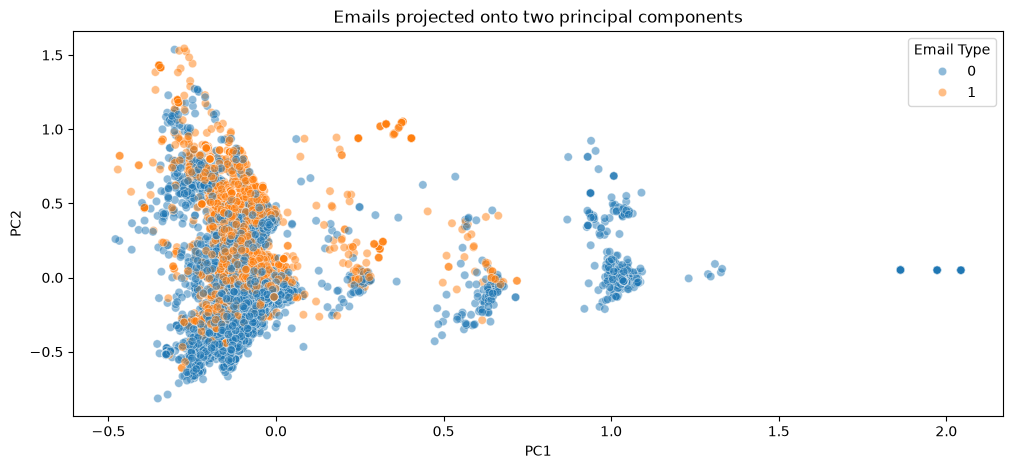

In [83]:
# q3
plt.figure(figsize=(12, 5))

sns.scatterplot(
    data=plot_df,
    x='PC1',
    y='PC2',
    hue='Email Type',
    alpha=0.5
)

plt.title('Emails projected onto two principal components')
plt.show()

**q3** After calculating the email's PC's and plotting them we can see that most scam emails denoted by the 1/orange dots are represented at a wide range of PC2's but mostly at 0.5 PC1 and below. Above a PC1 value of 1.0 it seems though all emails are real emails. At lower PC1 values there is a large amount of overlap between scam and real emails. PC2 does not seem to any significant correlation at determining whether an email is a scam or real.

### Q4

In [90]:
# q4
pca_reg = PCA(n_components=2610)
train_pcs = pca_reg.fit_transform(x_train)
test_pcs = pca_reg.transform(x_test)

pca_model = LinearRegression()

pca_model.fit(train_pcs, y_train)

pca_train_r2 = pca_model.score(train_pcs, y_train)
pca_test_r2 = pca_model.score(test_pcs, y_test)

print(f'pca training r2 score: {pca_train_r2:.4f}')
print(f'pca test r2 score: {pca_test_r2:.4f}')

pca training r2 score: 0.7662
pca test r2 score: 0.6683


**q4** compared to the q2 r2 scores, using pca did not change the scores by a noticeable amount. Both the scores themselves and their relative difference is about the same as the linear regression

### Q5
 

**q5** Using PCA allows for easier analysis of large amounts of data while avoiding certain issues that can arise in datasets such as overlap or noise. Features in large datasets could be heavily correlated, such as certain words being used together in our email example. PCA can combine these into unrelated components. PCA can also reduce noise by dropping smaller components. These smaller components hold less varience, therefore dropping them does not change the overall varience of the data much and can reduce noise in some cases.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** eff1ce8f8b3a7c8d8528f1f4456d41c3822972c2
- **AI tool and model used:** GPT 6.1 Sol

### *Prompts used

suggest any necessary changes: write out any suggest changes in a single list:

### *AI-proposed changes


1. Q3: Replace the claim about PC2 having no “significant correlation” with a visual observation: scam and non-scam emails overlap substantially along PC2. The scatterplot alone does not establish statistical significance.

2. Q5: Replace “unrelated components” with “uncorrelated components.” PCA forms weighted combinations of the original features; uncorrelated components are not necessarily independent.

3. Q5: Clarify that dropping components preserves most predictor variation when the discarded components collectively explain little variance. Those components may still contain useful information for predicting scams, so dropping them does not guarantee improved predictions.

4. Q5: Explicitly connect the explanation to regression: retaining fewer components reduces the number of predictors and can reduce instability or overfitting.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Simple change that is accurate |
| 2 | Accept | Simple change that is accurate |
| 3 | Accept | Simple change that is accurate |
| 4 | Accept | Simple change that is accurate |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

**q3** After calculating the email's PC's and plotting them we can see that most scam emails denoted by the 1/orange dots are represented at a wide range of PC2's but mostly at 0.5 PC1 and below. Above a PC1 value of 1.0 it seems though all emails are real emails. At lower PC1 values there is a large amount of overlap between scam and real emails. *Scam and real emails seems to overlap substatially across PC2*

**q5** Using PCA allows for easier analysis of large amounts of data while avoiding certain issues that can arise in datasets such as overlap or noise. Features in large datasets could be heavily correlated, such as certain words being used together in our email example. PCA can combine these into *uncorrelated* components. PCA can also reduce noise by dropping smaller components. These smaller components hold less varience, therefore dropping them does not change the overall varience of the data much and can *reduce instability or overfitting as retaining fewer components reduces the number of predictors. Despite this, this data still contains information related to predicting scams so may not imrpove predictions.*

### *Reflection on AI assistance
In your own words without generative AI.

This week I tried using OpenAI's integrated vscode codex extension, which made asking the phase 2 question and formatting it much easier. Having ChatGPT integrated into the actual IDE and having direct access probably did not change the actual content of the response, but the overall process felt smoother and more streamlined than having to upload the notebook to the web client. Overall this weeks revisions were fairly simple and all explanation based questions so I had no issue implementing them as italicized areas of their respective answers even if they were redundant to the actual code or outputs. I think that having the overall process be streamlined through the sidebar use of codex lowered the barrier to implement the changes which I was too bothered to perform for previous labs. Overall I am satisfied with this weeks labs and the AI revision provided and will continue to perform phase 2 of labs in this method from now on.